In [1]:
import pandas as pd
import json
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

print("Biblioteker lastet inn!")

W1124 11:18:32.973000 75371 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Biblioteker lastet inn!


In [25]:
#Last inn renset datasett

with open("../data/diagnoses_clean.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)
print(f"Lastet {len(df)} diagnoser")
df.head()

Lastet 3103 diagnoser


,id,diagnosis,diagnosis_clean
0,ID_0001,hysteria ?,hysteria ?
1,ID_0002,hysteria 7,hysteria 7
2,ID_0003,hysteria,hysteria
3,ID_0004,202|hysteria,202|hysteria
4,ID_0005,hysteria,hysteria


In [26]:
# Last inn en flerspråklig modell som forstår norsk
model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

# Lag embeddings
embeddings = model.encode(df["diagnosis_clean"].tolist())

print(f"Embeddings laget: {embeddings.shape}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embeddings laget: (3103, 384)


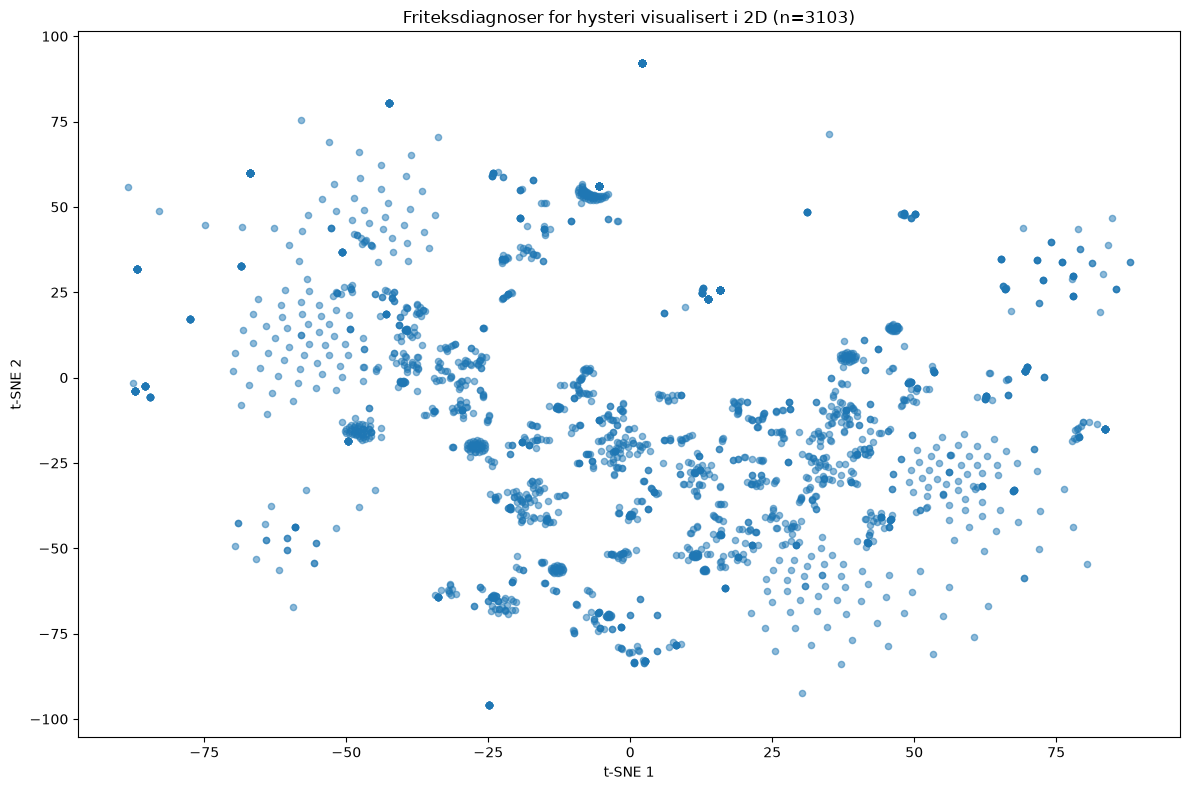

Plot lagret!


In [27]:
# Reduser fra 384 dimensjoner til 2 (for å kunne plotte)
# Med så lite data bruker vi perplexity=2
tsne = TSNE(n_components=2, random_state=42, perplexity=15)
coords = tsne.fit_transform(embeddings)

# Plot
fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(coords[:, 0], coords[:, 1], s=20, alpha=0.5)

ax.set_title("Friteksdiagnoser for hysteri visualisert i 2D (n=3103)")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
plt.tight_layout()
plt.savefig("../results/diagnose_kart.png", dpi=150)
plt.show()

print("Plot lagret!")

In [ ]:
# Finn de mest isolerte punktene
# (de med størst avstand fra sentrum)
avstand = np.sqrt(coords[:, 0]**2 + coords[:, 1]**2)
df["avstand"] = avstand
df.nlargest(10, "avstand")[["id", "diagnosis"]]

In [ ]:
from sklearn.neighbors import NearestNeighbors

# Finn avstand til nærmeste nabo for hvert punkt
nn = NearestNeighbors(n_neighbors=2)
nn.fit(coords)
avstander, _ = nn.kneighbors(coords)

# Nærmeste nabo er indeks 1 (indeks 0 er punktet selv)
df["nabo_avstand"] = avstander[:, 1]

pd.set_option("display.max_colwidth", None)

# Vis de 15 mest isolerte
topp_isolerte = df.nlargest(15, "nabo_avstand")[["id", "diagnosis", "nabo_avstand"]]
print("De 15 mest isolerte diagnosene:")
topp_isolerte

In [ ]:
# Lagre embeddings som numpy-fil
np.save("../data/embeddings.npy", embeddings)
print("Embeddings lagret!")

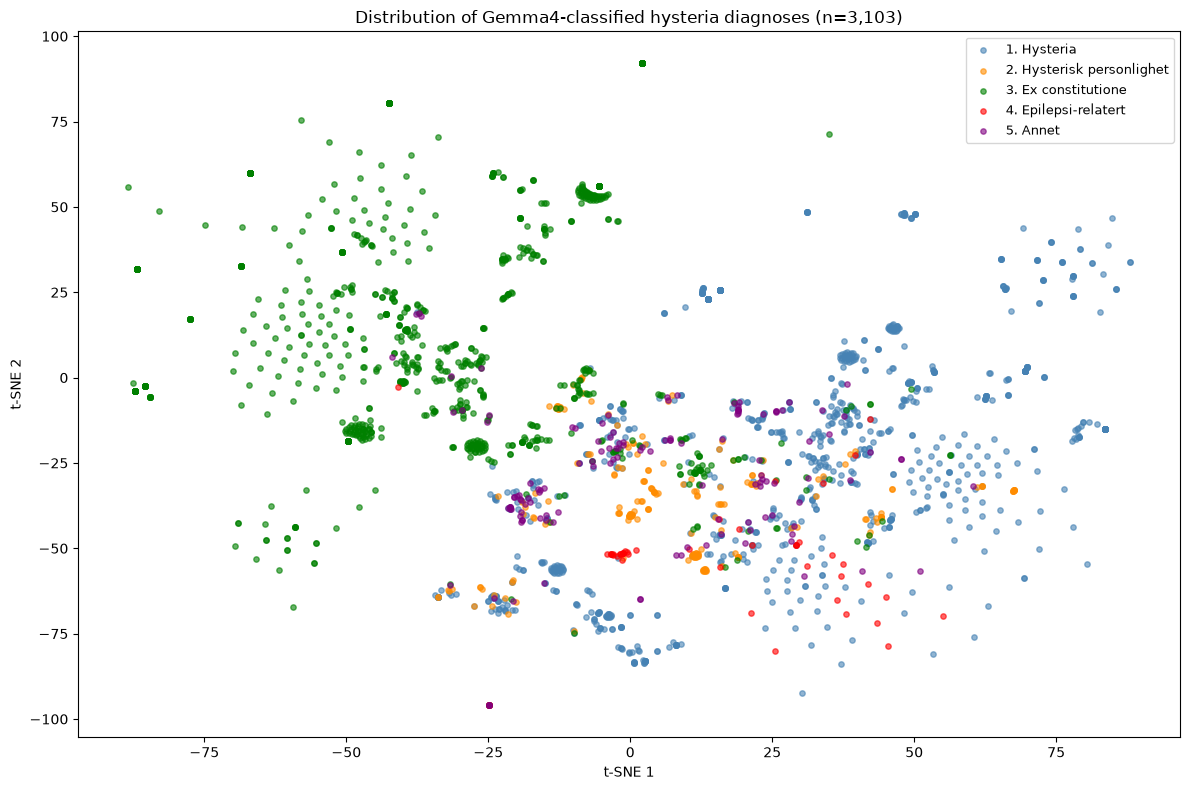

In [28]:
# Last inn klassifiserte data og lage plot

df_klassifisert = pd.read_json("../data/klassifisert.json")

# Farger per kategori
farger = {
    "1. Hysteria": "steelblue",
    "2. Hysterisk personlighet": "darkorange",
    "3. Ex constitutione": "green",
    "4. Epilepsi-relatert": "red",
    "5. Annet": "purple"
}

fig, ax = plt.subplots(figsize=(12, 8))

for kategori, farge in farger.items():
    maske = df_klassifisert["kategori"] == kategori
    ax.scatter(coords[maske, 0], coords[maske, 1],
               c=farge, label=kategori, s=15, alpha=0.6)

ax.set_title("Distribution of Gemma4-classified hysteria diagnoses (n=3,103)")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig("../results/diagnose_kart_farger.png", dpi=150)
plt.show()

In [ ]:
tsne_3d = TSNE(n_components=3, random_state=42, perplexity=30)
coords_3d = tsne_3d.fit_transform(embeddings)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

for kategori, farge in farger.items():
    maske = df_klassifisert["kategori"] == kategori
    ax.scatter(coords_3d[maske, 0], coords_3d[maske, 1], coords_3d[maske, 2],
               c=farge, label=kategori, s=15, alpha=0.6)

ax.set_title("Diagnoser i 3D")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()